In [8]:
!pip list

Package                  Version
------------------------ --------------------
absl-py                  2.5.0
asttokens                3.0.2
astunparse               1.6.3
attrs                    26.1.0
certifi                  2026.7.22
cffi                     2.1.1
charset-normalizer       3.5.2
colorama                 0.4.6
comm                     0.2.3
contourpy                1.3.3
cycler                   0.12.1
debugpy                  1.8.21
decorator                5.3.1
dill                     0.4.1
dm-tree                  0.1.10
docstring_parser         0.18.0
einops                   0.8.2
etils                    1.14.0
executing                2.2.1
fastjsonschema           2.21.2
flatbuffers              25.12.19
fonttools                4.63.0
fsspec                   2026.9.0
gast                     0.7.0
google-pasta             0.2.0
googleapis-common-protos 1.75.5
grpcio                   1.84.0
h5py                     3.15.1
idna                     3.20
im

In [9]:
#Bring tensorflow
import tensorflow as tf
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu,True)

In [10]:
#Bringing in tesnorflow dataset for fashion minst
import tensorflow_datasets as  tdfs
#Bringing in matplotlib for viz stuff
from matplotlib import pyplot as plt

In [11]:
!pip install importlib_resources

import tensorflow as tf
import tensorflow_datasets as tfds
from matplotlib import pyplot as plt

#Configure GPU memory growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# Load the dataset successfully
ds = tfds.load('fashion_mnist',split= 'train')
print("Enviorement initialized and dataset 'ds' loaded successfully! ")

Enviorement initialized and dataset 'ds' loaded successfully! 


In [12]:
ds.as_numpy_iterator().next()['label']

np.int64(2)

## 2. Visualising data and building the dataset

In [13]:
# To do some data transformation we require the numpy library
import numpy as np

In [14]:
#Setup  connection aka iterator
dataiterator = ds.as_numpy_iterator()

In [15]:
#Getting data out of the pipeline
dataiterator.next()['image']

array([[[  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [ 18],
        [ 77],
        [227],
        [227],
        [208],
        [210],
        [225],
        [216],
        [ 85],
        [ 32],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0]],

       [[  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [ 61],
        [100],
        [ 97],
        [ 80],
        [ 57],
        [117],
        [227],
        [238],
        [115],
        [ 49],
        [ 78],
        [106],
        [108],
        [ 71],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0]],

       [[  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [ 81],
        [105],
        [ 80],
        [ 69],
      

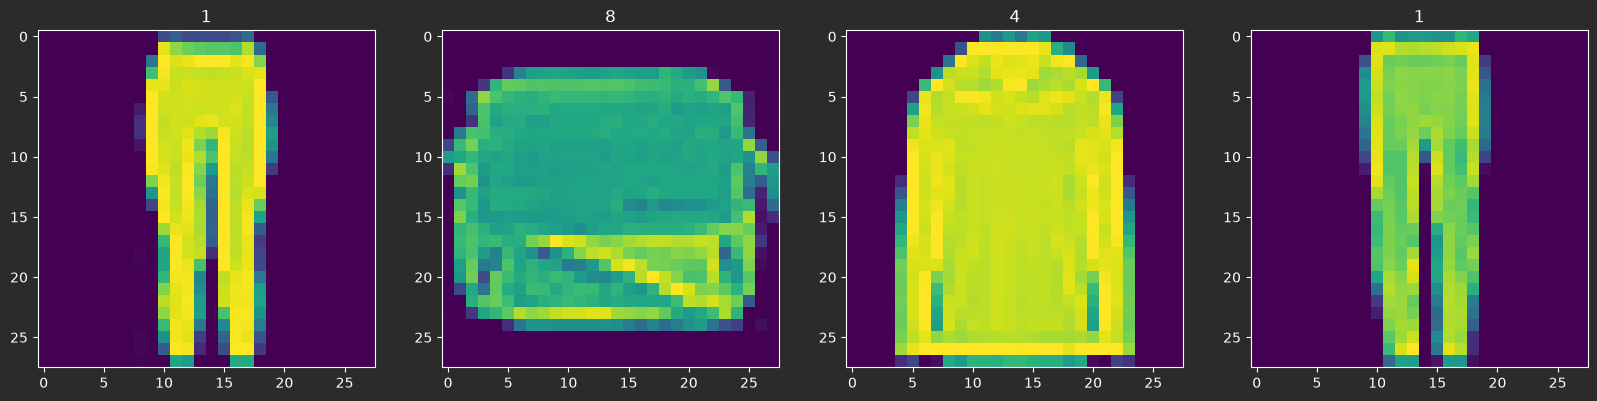

In [16]:
#Setup the subplot formatting
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
#Loop four times and get images
for idx in range(4):
    # Grab an image and label
    sample = dataiterator.next()
    #Plot the image using a specific subplot
    ax[idx].imshow(sample['image'])
    #appending the image label as plot title
    ax[idx].title.set_text(sample['label'])


In [17]:
#Scale and return images only
def scale_images(data):
    image = data['image']
    return image/255

In [18]:
#Reload the dataset
ds = tfds.load('fashion_mnist', split= 'train')
ds = ds.map(scale_images)
ds = ds.cache()
ds = ds.shuffle(60000)
ds = ds.batch(128)
ds = ds.prefetch(64)

In [19]:
ds.as_numpy_iterator().next().shape

(128, 28, 28, 1)

## 3. Bulding a neural network

In [20]:
#Bring in sequential api for generator and discriminator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D , Dense , Flatten , Reshape , LeakyReLU , Dropout , UpSampling2D

In [21]:
#Building a Generator
def build_generator():
    model = Sequential()
    #Takes a random values and reshapes it into 7X7X128
    #Beggingins of  a generated image
    model.add(Dense(7*7*128 , input_dim=128))
    model.add(LeakyReLU(0.2))
    model.add(Reshape((7,7,128)))

    #Upsampling Block 1
    model.add(UpSampling2D())
    model.add(Conv2D(128 , 5 , padding='same'))
    model.add(LeakyReLU(0.2))

    #Upsampling Block 2
    model.add(UpSampling2D())
    model.add(Conv2D(128 , 5 , padding='same'))
    model.add(LeakyReLU(0.2))


    #Convonulation Block 1
    model.add(Conv2D(128 , 4 , padding='same'))
    model.add(LeakyReLU(0.2))

    #Cononulation Block 2
    model.add(Conv2D(128 , 4, padding='same'))
    model.add(LeakyReLU(0.2))


    #Conv layer  to get to one channel
    model.add(Conv2D(1, 7 , padding='same' , activation = 'sigmoid'))

    return model

In [22]:
generator = build_generator()

In [23]:
generator.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 6272)           │       809,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 128)    │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 128)    │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 128)    │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 1)      │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,159,361 (8.24 MB)

 Trainable params: 2,159,361 (8.24 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
img = generator.predict(np.random.randn(4,128,1,))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


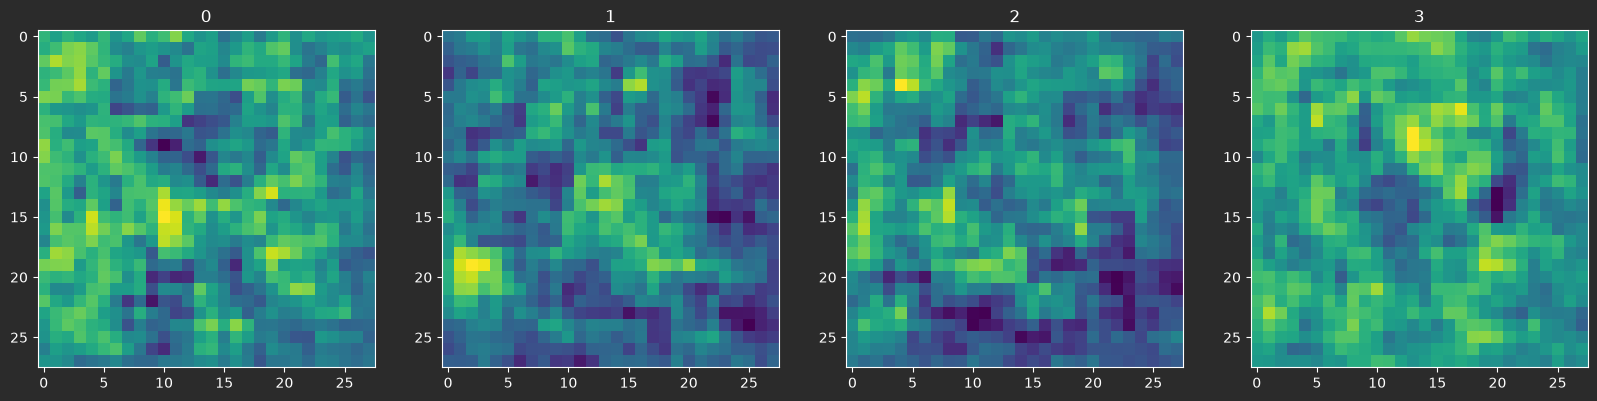

In [25]:
# Generate new fashion
img = generator.predict(np.random.randn(4,128,1))
# Setup the subplot formatting
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
# Loop four times and get images
for idx, img in enumerate(img):
    # Plot the image using a specific subplot
    ax[idx].imshow(np.squeeze(img))
    # Appending the image label as the plot title
    ax[idx].title.set_text(idx)

## 3.1 Building Discriminator